# Utilizando ML para criar um modelo preditivo de pacientes com diabetes.
Foi solicitado por um laboratório, que com base em dados de pacientes que realizaram exames de diabetes, um modelo que possa prever com base em caracteristicas como idade, peso e altura, qual o resultado esperado do exampe para novos pacientes. Desta forma, irei treinar um algoritmo supervisionado, tendo em vista que possuimos dados reais dos resultados para criar um modelo peditivo que atenda essa necessidade.

### Importando as bibliotecas utilizadas e o dataset

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [84]:
#Carregando o arquivo para um dataframe
df_exames = pd.read_csv('./datasets/exame_diabetes.csv')
df_exames.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id_paciente  100 non-null    int64
 1   genero       100 non-null    str  
 2   idade        100 non-null    int64
 3   peso         100 non-null    int64
 4   altura       100 non-null    int64
 5   resultado    100 non-null    int64
dtypes: int64(5), str(1)
memory usage: 4.8 KB


In [85]:
#Percebemos que o dataset recebido não possui valores nulos. Em modelos de "regressão", onde iremos prever valores com base nos resultados
# a coluna de id_paciente não é relevante para a nossa analise, então podemos removê-la do dataset.
df_exames.drop(columns=['id_paciente'], inplace=True)

C:\Users\Felipe\AppData\Local\Temp\ipykernel_23792\2586501338.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_exames.drop(columns=['id_paciente'], inplace=True)


In [86]:
#Outro ponto importante é que em modelos de ML costumamos não fazer uso de valores que não sejam numéricos, por exe mplo, a coluna de sexo. Então podemos remover ou modificar os valores
# Neste caso, podemos transformar a coluna de sexo em uma variável dummy, tendo em vista que é uma informação que impacta no resultado do exame.
df_exames = pd.get_dummies(df_exames, columns=['genero'], dtype=int)



In [87]:
df_exames.head()

,idade,peso,altura,resultado,genero_F,genero_M
0,46,83,165,98,0,1
1,23,83,164,82,1,0
2,39,71,154,93,0,1
3,26,103,165,95,1,0
4,27,55,176,100,0,1


<Axes: >

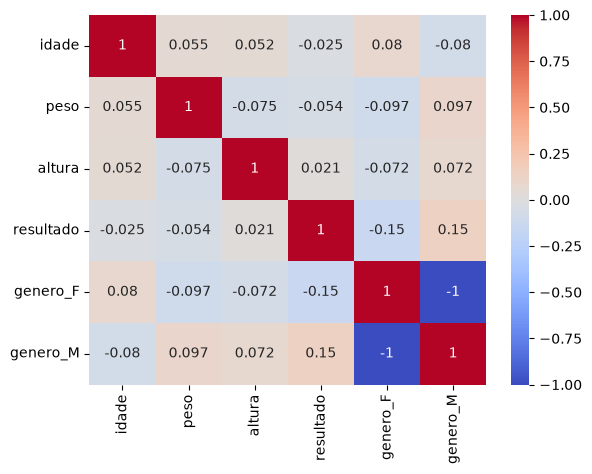

In [88]:
# Vamos utilizar um gráfico (mapa de calor), para verificar se existe alguma correlação entre as variáveis do dataset. 
# A correlação é uma medida estatística que indica o quanto duas variáveis estão relacionadas.
sns.heatmap(df_exames.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)

array([[<Axes: xlabel='idade', ylabel='idade'>,
        <Axes: xlabel='peso', ylabel='idade'>,
        <Axes: xlabel='altura', ylabel='idade'>,
        <Axes: xlabel='resultado', ylabel='idade'>,
        <Axes: xlabel='genero_F', ylabel='idade'>,
        <Axes: xlabel='genero_M', ylabel='idade'>],
       [<Axes: xlabel='idade', ylabel='peso'>,
        <Axes: xlabel='peso', ylabel='peso'>,
        <Axes: xlabel='altura', ylabel='peso'>,
        <Axes: xlabel='resultado', ylabel='peso'>,
        <Axes: xlabel='genero_F', ylabel='peso'>,
        <Axes: xlabel='genero_M', ylabel='peso'>],
       [<Axes: xlabel='idade', ylabel='altura'>,
        <Axes: xlabel='peso', ylabel='altura'>,
        <Axes: xlabel='altura', ylabel='altura'>,
        <Axes: xlabel='resultado', ylabel='altura'>,
        <Axes: xlabel='genero_F', ylabel='altura'>,
        <Axes: xlabel='genero_M', ylabel='altura'>],
       [<Axes: xlabel='idade', ylabel='resultado'>,
        <Axes: xlabel='peso', ylabel='resultado'>,


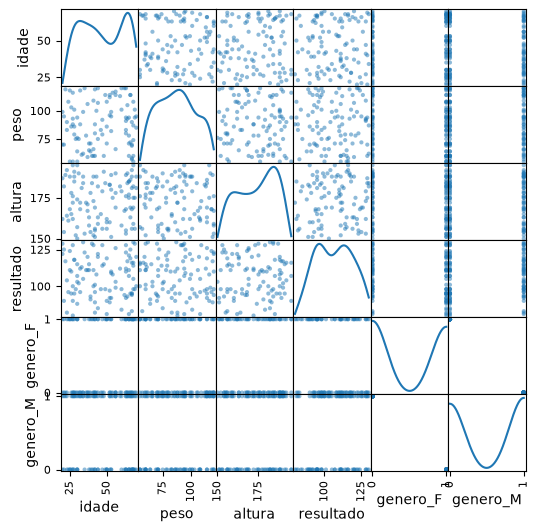

In [89]:
#plot de scatter (Dispersão) com distribuição.
pd.plotting.scatter_matrix(df_exames, figsize=(6, 6), diagonal='kde', alpha=0.5)

In [90]:
#Criar uma feature nova que será o IMC.
# a altura está em cm, então precisamos dividir por 100 para transformar em metros (dividindo por 100).
df_exames['imc'] = (df_exames['peso'] / ((df_exames['altura']/100)** 2))

In [91]:
df_exames.head()

,idade,peso,altura,resultado,genero_F,genero_M,imc
0,46,83,165,98,0,1,30.486685
1,23,83,164,82,1,0,30.859607
2,39,71,154,93,0,1,29.937595
3,26,103,165,95,1,0,37.832874
4,27,55,176,100,0,1,17.755682


In [92]:
#importando bibliotecas para o modelo de regressão linear.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

In [93]:
df_exames.head()

,idade,peso,altura,resultado,genero_F,genero_M,imc
0,46,83,165,98,0,1,30.486685
1,23,83,164,82,1,0,30.859607
2,39,71,154,93,0,1,29.937595
3,26,103,165,95,1,0,37.832874
4,27,55,176,100,0,1,17.755682


In [94]:
# Vamos criar dois modelos, um com peso e altura sem IMC e outro com IMC, para verificar qual modelo tem melhor performance.

#Modelo 1 - Sem IMC
#Definindo as variáveis independentes (X) e a variável dependente (y)
X = df_exames.drop(columns=['imc', 'resultado'])
Y = df_exames['resultado']

In [95]:
#Dividindo conjunto entre treino e teste
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.7, random_state=51)

In [96]:
#Com os dados separados, podemos fazer o treinamento do modelo, utilizando a função fit() do modelo de regressão linear.
#Criando o modelo de regressão linear - Modelo 1
model_1 = LinearRegression().fit(X_train, Y_train)


In [97]:
#Gerando predições do conjunto de teste com base no modelo 1
y_pred = model_1.predict(X_test)

In [98]:
#Verificando em escala o quanto que x explica y, ou seja, o quanto que o modelo consegue prever com base nos dados de teste.
r2_score(Y_test, y_pred)

-0.2639179004021748

In [99]:
#R2 Score - Conjunto treinamento
model_1.score(X_train, Y_train)

0.07260818476640707

In [100]:
model_1.score(X_test, Y_test)

-0.2639179004021748

In [101]:
#MAE - Mean Absolute Error - Erro médio absoluto, ou seja, a média do erro absoluto entre o valor real e o valor previsto.
mean_absolute_error(Y_test, y_pred)

13.466664869862774

In [102]:
#Treinando o modelo 2, que será com a variável IMC.
#Modelo 2 - Com IMC

X = pd.DataFrame(df_exames['imc'])
Y = df_exames['resultado']

In [103]:
#Dividindo o conjunto entre treino e teste
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.7, random_state=51)

In [104]:
#Treinando o algoritmo de regressão linear com a variável IMC
model_2 = LinearRegression().fit(X_train, Y_train)

In [105]:
#Gerando predições do conjunto de teste com base no modelo 2
y_pred = model_2.predict(X_test)

In [106]:
model_2.coef_

array([-0.11063088])

In [107]:
model_2.intercept_

np.float64(111.25271478972051)

In [108]:
#R2 Score - Conjunto treinamento
model_2.score(X_train, Y_train)

0.004837831252090474

In [109]:
#R2 Score - Conjunto teste
model_2.score(X_test, Y_test)

-0.027018925594941123

In [110]:
#MAE - Mean Absolute Error - Erro médio absoluto, ou seja, a média do erro absoluto entre o valor real e o valor previsto.
mean_absolute_error(Y_test, y_pred)

12.247767098480901

Text(0.5, 1.0, 'Regressão Linear - Predição de Diabetes com IMC')

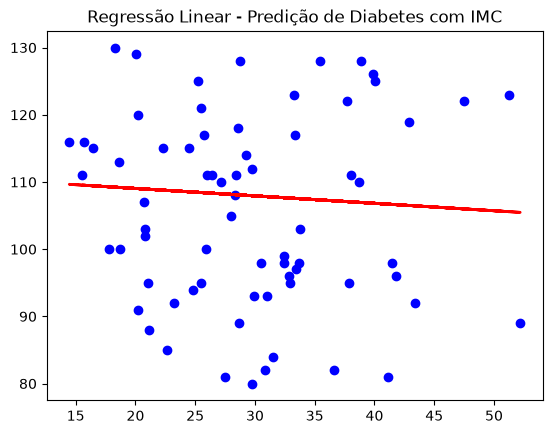

In [111]:
#Gerando um gráfico de correlação entre as variáveis do dataset
plt.scatter(X_test, Y_test, color='blue', label='Dados Reais')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Predições do Modelo')
plt.title('Regressão Linear - Predição de Diabetes com IMC')